# 7. Area, level and radar: where the differences actually show

Per pixel, a tuned NDWI threshold beats the U-Net, which in turn is probably ahead of MNDWI
(notebook 6). But nobody monitoring a reservoir cares about individual pixels. They care about **how much water there is, and whether that number is
right every time**, including on cloudy days. This notebook maps every usable date from 2018 to
2026 and compares lake area with the official record.

In [1]:
from hlw.nb import BLUE, GREEN, GREY, INK, ORANGE, setup

PURPLE = "#7a5af5"  # NDWI

setup()
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from hlw import config as C
from hlw import levels
from hlw.analyze import load_timeline

LAKES = C.lakes()
tl = {k: load_timeline(k) for k in LAKES}
tl["travis"].groupby(["sensor", "kind"]).size().rename("dates mapped")

sensor  kind  
s1      all       255
s2      clear     121
        cloudy     30
Name: dates mapped, dtype: int64

For every lake: up to two fully clear Sentinel-2 dates per month (one for the steady lakes),
a sample of cloudy ones, and every Sentinel-1 pass. Each lake is mapped only by models that
never trained on it. The S2 numbers are areas inside the lake zone; TWDB numbers come from the
rating curve at that day's level.

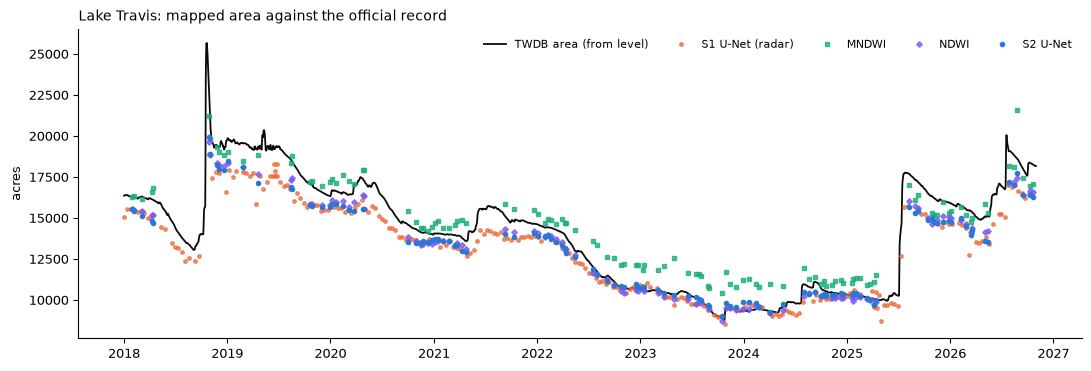

In [2]:
k = "travis"
d, lv = tl[k], levels.load(k)
s2 = d[(d.sensor == "s2") & (d.kind == "clear")]
s1 = d[(d.sensor == "s1") & (d.valid_frac > 0.95)]
fig, ax = plt.subplots(figsize=(11, 3.8))
ax.plot(lv.index, lv.surface_area, color=INK, lw=1.3, label="TWDB area (from level)")
ax.plot(s1.date, s1.area_model, "o", ms=2.5, color=ORANGE, alpha=0.7, label="S1 U-Net (radar)")
ax.plot(s2.date, s2.area_mndwi, "s", ms=3, color=GREEN, alpha=0.8, label="MNDWI")
ax.plot(s2.date, s2.area_ndwi, "D", ms=2.8, color=PURPLE, alpha=0.8, label="NDWI")
ax.plot(s2.date, s2.area_model, "o", ms=3, color=BLUE, label="S2 U-Net")
ax.set(ylabel="acres", title=f"{LAKES[k].name}: mapped area against the official record")
ax.legend(frameon=False, ncol=5, fontsize=8)
plt.tight_layout()

Everything tracks the big story: the 2018 flood, the long decline to the 2023 drought low (a
third of full area), and the July 2025 refill. Look closer and three things separate:

* The U-Net and NDWI sit **below** the TWDB line, most at high water. The rating curve counts
  flooded trees and the narrow upper river as lake, which a 10 m pixel doesn't see as water.
* **MNDWI** (green squares), with its low tuned cutoff (−0.26 at Travis), sits slightly
  *above* TWDB on average and scatters more. Where a method sits relative to TWDB depends a lot
  on its cutoff, which is why the next test ignores constant offsets.
* **NDWI** (purple) and the **S2 U-Net** (blue) almost overlap.
* **Radar** (orange) follows the same curve as the optical U-Net, at twice the density.

Because the offset from TWDB is partly about definitions, the fairest single test is how
tightly each method's area follows the **level**, plus the error left after one straight-line
calibration (which absorbs any constant definitional difference):

In [3]:
avl = pd.read_csv(C.RESULTS_DIR / "area_vs_level.csv")
cols = ["lake", "method", "n", "r_level", "rmse_acres", "rmse_after_linear_acres", "mape_pct"]
avl[avl.lake.isin(["travis", "buchanan"])][cols].round(3)

,lake,method,n,r_level,rmse_acres,rmse_after_linear_acres,mape_pct
0,buchanan,S2 U-Net (ensemble),148,0.992,925.055,212.812,3.960
1,buchanan,NDWI threshold,148,0.993,991.961,211.310,4.622
2,buchanan,"NDWI, per-scene Otsu",148,0.994,1009.599,226.312,4.745
3,buchanan,MNDWI threshold,148,0.993,1017.434,235.394,4.678
4,buchanan,S2 SCL water class,148,0.910,2039.139,1077.587,7.908
5,buchanan,S1 U-Net,250,0.988,730.231,312.316,3.100
6,buchanan,S1 VV threshold,250,0.565,3985.914,2245.109,14.145
28,travis,S2 U-Net (ensemble),121,0.990,1013.549,363.792,4.908
29,travis,NDWI threshold,121,0.994,892.392,327.798,4.355
30,travis,"NDWI, per-scene Otsu",121,0.961,1099.151,913.246,6.472


**On optical area, NDWI matches the U-Net.** At Travis, NDWI's area follows the level with
r = 0.994 against the U-Net's 0.990, and after calibration its typical error is 328 acres
against 364. At Buchanan the two are indistinguishable (211 vs 213 acres). MNDWI is clearly
behind at Travis (r = 0.972, 727 acres) and close at Buchanan.

So the per-pixel ranking carries over to area, mostly. NDWI's per-pixel lead over the U-Net
shrinks to a near tie over whole lakes, because both are very good on open water and differ
mainly at the edges. MNDWI's per-pixel deficit, on the other hand, grows. Its errors are
**systematic**: on bright or hazy dates it misjudges water across the whole lake at once
(notebook 2), and those misses add up. A small per-pixel difference in the wrong places becomes
a large difference in total area.

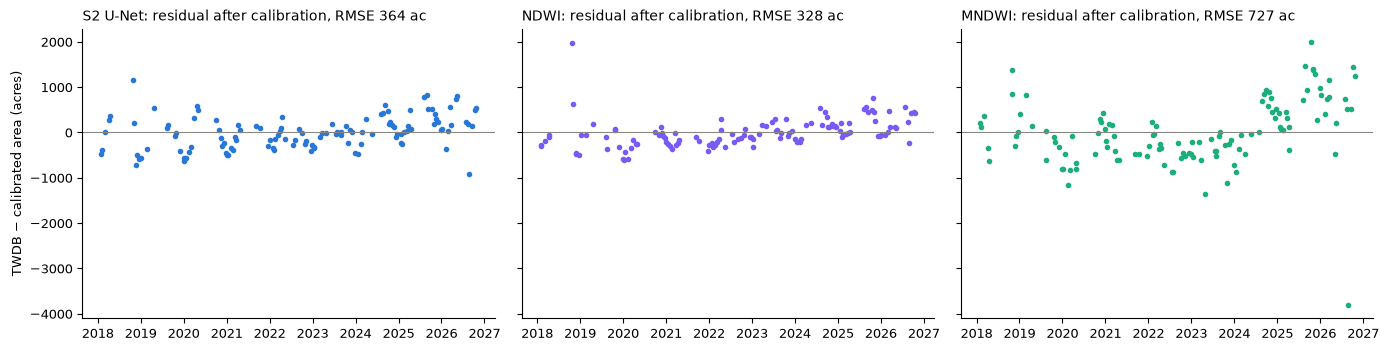

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.6), sharey=True)
for ax, (col, name, c) in zip(axes, (("area_model", "S2 U-Net", BLUE),
                                     ("area_ndwi", "NDWI", PURPLE),
                                     ("area_mndwi", "MNDWI", GREEN))):
    x, y = s2[col].values, s2.twdb_area.values
    ok = np.isfinite(x) & np.isfinite(y)
    a, b = np.polyfit(x[ok], y[ok], 1)
    resid = y[ok] - (a * x[ok] + b)
    ax.plot(s2.date[ok], resid, "o", ms=3, color=c)
    ax.axhline(0, color=GREY, lw=0.8)
    ax.set(title=f"{name}: residual after calibration, RMSE {np.sqrt(np.mean(resid**2)):,.0f} ac")
axes[0].set_ylabel("TWDB − calibrated area (acres)")
plt.tight_layout()

The U-Net and NDWI residuals look alike: a slow wander of a few hundred acres, mostly shared,
which probably belongs to the rating curve or the lake zone rather than to either method.
MNDWI's residuals swing much more, and in step with the lake: its calibrated area runs high
through the 2020-2024 low-water years and low after the 2025 refill, with one bad date in
2026. Its cutoff treats low-water and high-water scenes differently, and no single straight
line can fix that.

## Clouds: what optical mapping reports when it can't see

In [5]:
cl = pd.read_csv(C.RESULTS_DIR / "cloudy.csv")
cl[cl.lake.isin(["travis", "buchanan"])].pivot_table(index="case", columns="lake",
                                                    values="median_abs_err_pct").round(1)

lake,buchanan,travis
case,,
"S1 U-Net, all dates",3.0,6.2
"S1 U-Net, dates with no clear S2 within 3 days",3.0,6.5
"S2 U-Net, clear dates",4.3,4.6
"S2 U-Net, cloudy dates (clouds left in)",11.7,10.4
"S2 U-Net, cloudy dates (clouds masked)",29.5,36.0
months with a usable observation: S2 clear + S1,100.0,100.0
months with a usable observation: S2 clear only,84.0,69.8


Read the rows in pairs:

* **Clouds left in.** The model labels cloud tops and runs on. Median error doubles, and the
  worst cases are wild: on 3 February 2023 at Travis it mapped 45,401 acres, nearly twice the
  lake's full size, when TWDB said 10,540.
* **Clouds masked.** Throwing away cloudy pixels is worse for area (30-36 % error): you simply
  don't count the water under the cloud. A partly cloudy optical image cannot give a lake area.
* **Radar on the dates optical can't cover** (no clear S2 within ±3 days): 6.5 % and 3.0 %
  median error. On 4 February 2023, the day after that failed optical pass, the S1 U-Net mapped
  10,750 acres.

The last two rows are the payoff: optical alone gives a usable map in 70 % (Travis) and 84 %
(Buchanan) of months, and adding radar gives 100 %.

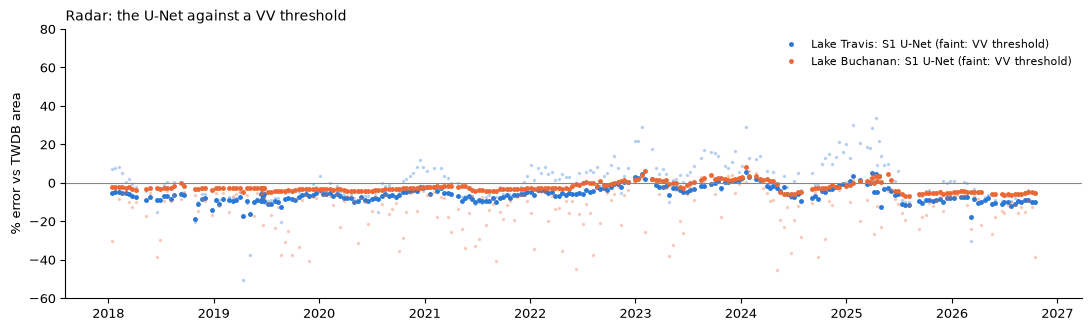

In [6]:
fig, ax = plt.subplots(figsize=(11, 3.4))
for k, c in (("travis", BLUE), ("buchanan", ORANGE)):
    d = tl[k]
    s1k = d[(d.sensor == "s1") & (d.valid_frac > 0.95)].dropna(subset=["twdb_area"])
    err_m = 100 * (s1k.area_model - s1k.twdb_area) / s1k.twdb_area
    err_v = 100 * (s1k.area_vv - s1k.twdb_area) / s1k.twdb_area
    ax.plot(s1k.date, err_v, ".", ms=3, color=c, alpha=0.25)
    ax.plot(s1k.date, err_m, "o", ms=2.5, color=c, label=f"{LAKES[k].name}: S1 U-Net (faint: VV threshold)")
ax.axhline(0, color=GREY, lw=0.8)
ax.set(ylim=(-60, 80), ylabel="% error vs TWDB area", title="Radar: the U-Net against a VV threshold")
ax.legend(frameon=False, fontsize=8)
plt.tight_layout()

This is the clearest deep-learning win in the project, and there is no index alternative that
comes close. The VV threshold (faint dots) swings by
tens of percent with wind and season. At Buchanan its area correlates with level at only
r = 0.57. The radar U-Net, trained by distillation from the optical model, tracks the level at
r = 0.99 at both lakes. Unlike the optical comparison, this gap doesn't depend on a handful of
pixels: it is large on every summary.

## The steady lakes: noise floor, and two surprises

On Inks, LBJ and Marble Falls the level usually sits within half a foot of normal, so on those
days the true area barely changes. The spread of mapped area on such days is the **noise
floor**: how much a method wobbles when nothing is happening.

In [7]:
nf = pd.read_csv(C.RESULTS_DIR / "noise_floor.csv")
nf.pivot_table(index="method", columns="lake", values="cv_steady_pct").round(1)

lake,inks,lbj,marble_falls
method,,,
MNDWI threshold,5.6,2.2,7.3
NDWI threshold,3.5,1.2,3.4
S1 U-Net,3.6,2.3,6.9
S1 VV threshold,7.4,7.1,10.4
S2 SCL water class,5.4,2.7,5.9
S2 U-Net (ensemble),3.5,1.5,3.5


The S2 U-Net and NDWI are the steadiest (1.2-3.5 % coefficient of variation); MNDWI is up to
twice as noisy and the VV threshold far worse. But steadiness has a catch. During the rare **drawdowns** (level
held 4-8 ft low for 1-4 months), compare how much each method's area fell with how much the
official area fell:

In [8]:
dd = nf.pivot_table(index="method", columns="lake", values="drawdown_change_pct").round(0)
dd.loc["TWDB area"] = nf.groupby("lake").twdb_drawdown_change_pct.first().round(0)
dd

lake,inks,lbj,marble_falls
method,,,
MNDWI threshold,-27.0,-5.0,-15.0
NDWI threshold,-24.0,-7.0,-13.0
S1 U-Net,-23.0,-4.0,-15.0
S1 VV threshold,-17.0,-3.0,-14.0
S2 SCL water class,-15.0,-1.0,-2.0
S2 U-Net (ensemble),-19.0,-3.0,-6.0
TWDB area,-28.0,-14.0,-27.0


**Every method under-reports the drops, and the U-Net most.** At Marble Falls the official
area fell 27 %, MNDWI's 15 %, NDWI's 13 % and the U-Net's 6 %. Freshly exposed lakebed is wet,
dark mud. The U-Net keeps calling it water, which matches what the hand labels showed
(notebook 6): it leans towards each lake's usual outline. Part of its steadiness is
**sluggishness**. NDWI is just as steady on normal days and responds more when the lake drops,
so it wins on both counts here. A method that never changes has a perfect noise floor too, so noise and
responsiveness must always be checked together. (Caveat: only 3-6 clear dates per drawdown.)

The second surprise is in the reference itself. At the *same* water level, TWDB's area moves
between years:

In [9]:
nf.groupby("lake")[["median_level_ft", "twdb_area_at_median_level_first_year",
                    "twdb_area_at_median_level_last_year"]].first().round(1)

,median_level_ft,twdb_area_at_median_level_first_year,twdb_area_at_median_level_last_year
lake,,,
inks,887.2,751.1,789.2
lbj,824.7,6107.4,6406.5
marble_falls,736.4,540.5,600.6


At an unchanged level the official area steps up by 5 % (LBJ, 2020), 5 % (Inks, 2021-22) and
11 % (Marble Falls, 2020). Water didn't appear from nowhere. These look like **rating-curve
revisions** after new bathymetric surveys (not yet verified against TWDB's survey dates). The
satellite record, which doesn't use the curve, is what makes such steps visible.

## Takeaways

* Evaluate on the quantity people use (**area over time**), not only per pixel. Systematic
  per-pixel errors compound into area errors; random ones cancel.
* On optical imagery of these lakes, a tuned NDWI threshold is as good as the U-Net for lake
  area, and more responsive to small drawdowns. The model's clear advantages are elsewhere:
  radar, and an uncertainty map.
* Radar plus a distilled U-Net gives a **cloud-proof monthly record** that a radar threshold
  can't match.
* Always pair a noise-floor measure with a **responsiveness** measure.
* The reference data can be wrong, or change under you. An independent measurement is
  valuable precisely because it can catch that.

For these five lakes, which are gauged daily, satellite area mostly confirms the gauge. The
obvious next question is whether this works where there **is** no gauge.

Next: [8 · transfer to small reservoirs](08_transfer_small_reservoirs.ipynb)